# Notebook 1: Problem Framing, Data Cleaning & Exploratory Data Analysis (EDA)

> **Legacy notebook - not the authoritative training or dashboard workflow.** Historical cells calibrated and selected thresholds on overlapping validation rows, used test labels for permutation importance, and included code that could overwrite `app.py` or expose the dashboard. Use `train_model.py` for model selection and `finalize_test.py` once for the frozen test evaluation. The original `model.joblib` is preserved.

**Project Title:** Hospital Appointment No-Show Prediction Decision Support  
**Role:** Machine Learning Intern, Data Scientist Intern  
**Rubric Focus:** Criterion 1 (15 Marks) - Target horizon, quality checks, anomaly resolution, anti-leakage features, chronological split, and EDA.

## 1. Problem Formulation & Operational Scope
- **Business Problem:** Missed outpatient visits ('no-shows') average ~20%, leaving physician capacity idle. Indiscriminate robocalls create notification fatigue.
- **Decision Support Goal:** Predict missed appointments at booking time so clinic staff can prioritize courtesy reminder calls and schedule safe buffer slots.
- **Prediction Unit:** An individual scheduled appointment booking.
- **Target Variable:** `no_show` (1 = missed, 0 = attended).
- **Prediction Horizon:** Strictly booking time (`ScheduledDay`). Only information known at booking is permitted.
- **Governance Boundaries:**
  1. Clinical diagnosis flags (`hipertension`, `diabetes`, `alcoholism`, `handcap`) and sensitive demographics (`gender`, `scholarship`) are strictly excluded for fairness.
  2. Post-booking interventions (`sms_received`) are excluded to prevent temporal target leakage.
  3. Decision support only: the model never triggers automated cancellations or messages.


In [5]:
pip install numpy pandas matplotlib seaborn scikit-learn

  Using cached numpy-2.5.4-cp315-cp315-win_amd64.whl.metadata (6.6 kB)
  Using cached matplotlib-3.11.2-cp315-cp315-win_amd64.whl.metadata (80 kB)
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached scikit_learn-1.9.1-cp315-cp315-win_amd64.whl.metadata (9.3 kB)
  Using cached contourpy-1.4.0-cp315-cp315-win_amd64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached kiwisolver-1.5.1-cp315-cp315-win_amd64.whl.metadata (5.2 kB)
  Using cached pillow-13.0.0-cp315-cp315-win_amd64.whl.metadata (9.3 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
  Using cached scipy-1.18.1-cp315-cp315-win_amd64.whl.metadata (61 kB)
Using cached numpy-2.5.4-cp315-cp315-win_amd64.whl (12.7 MB)
   ---------------------------------------- 0.0/10.9 MB ? eta -:--:--
   --- ------------------------------------ 1.0/10.9 MB 6.6 MB/s eta 0:00:02
   ----------------- ---------------------- 4.7/10.9 MB 13.2 MB/s eta 0:00:01

In [22]:
pip install pyarrow

   ---------------------------------------- 0.0/29.8 MB ? eta -:--:--
   - -------------------------------------- 0.8/29.8 MB 8.8 MB/s eta 0:00:04
   ----- ---------------------------------- 4.2/29.8 MB 14.9 MB/s eta 0:00:02
   ----------- ---------------------------- 8.7/29.8 MB 17.2 MB/s eta 0:00:02
   ----------------- ---------------------- 13.1/29.8 MB 18.3 MB/s eta 0:00:01
   ----------------------- ---------------- 17.6/29.8 MB 18.9 MB/s eta 0:00:01
   ----------------------------- ---------- 21.8/29.8 MB 19.2 MB/s eta 0:00:01
   ----------------------------------- ---- 26.2/29.8 MB 19.4 MB/s eta 0:00:01
   ---------------------------------------  29.6/29.8 MB 19.7 MB/s eta 0:00:01
   ---------------------------------------- 29.8/29.8 MB 16.9 MB/s  0:00:01
Note: you may need to restart the kernel to use updated packages.


In [3]:
pip install joblib

  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)

   -------------------- ------------------- 1/2 [joblib]
   -------------------- ------------------- 1/2 [joblib]
   -------------------- ------------------- 1/2 [joblib]
   -------------------- ------------------- 1/2 [joblib]
   -------------------- ------------------- 1/2 [joblib]
   -------------------- ------------------- 1/2 [joblib]
   ---------------------------------------- 2/2 [joblib]

Note: you may need to restart the kernel to use updated packages.


In [6]:


import joblib

import time
import hashlib
from datetime import datetime
from pathlib import Path
from collections import defaultdict
from bisect import bisect_left

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.isotonic import IsotonicRegression
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    roc_auc_score, average_precision_score, brier_score_loss,
    precision_score, recall_score, f1_score, confusion_matrix
)


plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 110

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
print('Environment initialized with random seed 42.')


Environment initialized with random seed 42.


## 2. Data Sourcing & Integrity Verification
- Dataset: Kaggle Medical Appointment No-Shows by Joni Hoppen (CC BY-NC-SA 4.0).
- Verifying raw file integrity via SHA-256 checksum.


In [7]:


df_raw = pd.read_csv("KaggleV2-May-2016.csv")

print(f"Dataset loaded: {len(df_raw):,} rows")
print(df_raw.shape)

df_raw.head(3)

Dataset loaded: 110,527 rows
(110527, 14)


,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
0,2.987250e+13,5642903,F,2016-04-29T18:38:08Z,2016-04-29T00:00:00Z,62,JARDIM DA PENHA,0,1,0,0,0,0,No
1,5.589978e+14,5642503,M,2016-04-29T16:08:27Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,0,0,0,0,0,No
2,4.262962e+12,5642549,F,2016-04-29T16:19:04Z,2016-04-29T00:00:00Z,62,MATA DA PRAIA,0,0,0,0,0,0,No


## 3. Data Cleaning & Anomaly Resolution
5 quality checks and cleaning rules:
1. Standardize column names to `snake_case`.
2. Drop the 5 corrupted float `PatientId` records (e.g. `93779.52927`) and cast `patient_id` to `int64`.
3. Filter 1 negative age record (`age == -1`).
4. Filter 5 inverted date records (`appointment_day < scheduled_day`).
5. Drop prohibited clinical condition flags, demographics, and post-booking SMS.


In [8]:
rename_dict = {
    'PatientId': 'patient_id', 'AppointmentID': 'appointment_id', 'Gender': 'gender',
    'ScheduledDay': 'scheduled_day', 'AppointmentDay': 'appointment_day', 'Age': 'age',
    'Neighbourhood': 'neighbourhood', 'Scholarship': 'scholarship', 'Hipertension': 'hipertension',
    'Diabetes': 'diabetes', 'Alcoholism': 'alcoholism', 'Handcap': 'handcap',
    'SMS_received': 'sms_received', 'No-show': 'no_show'
}
df_clean = df_raw.rename(columns=rename_dict)
df_clean['no_show'] = (df_clean['no_show'] == 'Yes').astype(int)
df_clean['scheduled_day'] = pd.to_datetime(df_clean['scheduled_day']).dt.tz_localize(None)
df_clean['appointment_day'] = pd.to_datetime(df_clean['appointment_day']).dt.tz_localize(None)

# Detect anomalies
float_id_mask = (df_clean['patient_id'] % 1 != 0)
neg_age_mask = df_clean['age'] < 0
inv_date_mask = df_clean['appointment_day'].dt.normalize() < df_clean['scheduled_day'].dt.normalize()

print(f'Corrupted float patient_id records: {float_id_mask.sum()}')
print(f'Negative age records:               {neg_age_mask.sum()}')
print(f'Inverted date records:              {inv_date_mask.sum()}')

valid_mask = (~float_id_mask) & (~neg_age_mask) & (~inv_date_mask)
df_clean = df_clean[valid_mask].copy()
df_clean['patient_id'] = df_clean['patient_id'].astype(np.int64)

prohibited = ['hipertension', 'diabetes', 'alcoholism', 'handcap', 'gender', 'scholarship', 'sms_received']
df_clean = df_clean.drop(columns=prohibited)
print(f'Clean records: {len(df_clean):,} (Dropped {len(df_raw)-len(df_clean)} records total, 99.99% retention).')


Corrupted float patient_id records: 5
Negative age records:               1
Inverted date records:              5
Clean records: 110,516 (Dropped 11 records total, 99.99% retention).


## 4. Leak-Free Feature Engineering (At Booking Time)
- `lead_time_days`: Days elapsed between booking date and appointment date.
- `is_same_day`: Same-day appointment indicator.
- `scheduled_hour`: Hour of booking.
- `appointment_weekday`: Day of week.
- `age_group`: Demographic life-stage bands (`0-12`, `13-24`, `25-45`, `46-65`, `66+`).
- `prev_appointment_count` & `prev_no_show_rate`: Patient historical track record computed strictly using appointments prior to the booking date.


In [9]:
sched_date = df_clean['scheduled_day'].dt.normalize()
appt_date = df_clean['appointment_day'].dt.normalize()
df_clean['lead_time_days'] = (appt_date - sched_date).dt.days
df_clean['is_same_day'] = (df_clean['lead_time_days'] == 0).astype(int)
df_clean['scheduled_hour'] = df_clean['scheduled_day'].dt.hour.astype(int)
df_clean['appointment_weekday'] = df_clean['appointment_day'].dt.day_name()

age_bins = [-1, 12, 24, 45, 65, 125]
age_labels = ['0-12', '13-24', '25-45', '46-65', '66+']
df_clean['age_group'] = pd.cut(df_clean['age'], bins=age_bins, labels=age_labels).astype(str)

# Leak-free prior history using timeline binary search
patient_appts = defaultdict(list)
for pid, adate, ns in zip(df_clean['patient_id'], appt_date, df_clean['no_show']):
    patient_appts[pid].append((adate, ns))
for pid in patient_appts:
    patient_appts[pid].sort(key=lambda x: x[0])

patient_timeline = {}
for pid, appts in patient_appts.items():
    dates = [x[0] for x in appts]
    cum_ns = [0]
    for x in appts:
        cum_ns.append(cum_ns[-1] + x[1])
    patient_timeline[pid] = (dates, cum_ns)

n = len(df_clean)
prev_counts = np.zeros(n, dtype=int)
prev_no_shows = np.zeros(n, dtype=int)
for i, (pid, sdate) in enumerate(zip(df_clean['patient_id'], sched_date)):
    dates, cum_ns = patient_timeline[pid]
    idx = bisect_left(dates, sdate)
    prev_counts[i] = idx
    prev_no_shows[i] = cum_ns[idx]

df_clean['prev_appointment_count'] = prev_counts
df_clean['prev_no_show_rate'] = np.divide(prev_no_shows, prev_counts, out=np.zeros(n, dtype=float), where=(prev_counts > 0))
df_clean['has_history'] = (prev_counts > 0).astype(int)

# Automated leakage checks
assert (df_clean['lead_time_days'] >= 0).all(), 'Negative lead times found!'
first_visits = df_clean.sort_values('scheduled_day').groupby('patient_id').first()
assert (first_visits['prev_appointment_count'] == 0).all(), 'Initial visits have non-zero prior count!'
print('All leak-free feature engineering and assertions passed!')


All leak-free feature engineering and assertions passed!


## 5. Exploratory Data Analysis & Healthcare Stories
We analyze empirical attendance trends to understand operational drivers:


Overall Dataset No-Show Rate: 20.19% (22,314 missed appointments)


C:\Users\mailt\AppData\Local\Temp\ipykernel_17340\1424823873.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=lead_summary, x='lead_bucket', y='mean', palette='Blues_d')


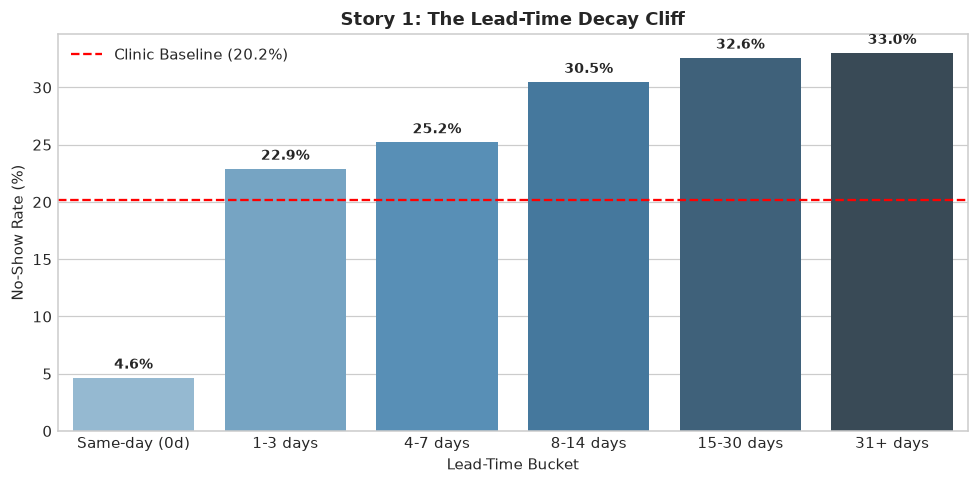

In [10]:
# Overall No-Show Rate
overall_rate = df_clean['no_show'].mean()
print(f'Overall Dataset No-Show Rate: {overall_rate:.2%} ({df_clean.no_show.sum():,} missed appointments)')

# Story 1: Lead-Time Decay Cliff
lead_bins = [-1, 0, 3, 7, 14, 30, 999]
lead_labels = ['Same-day (0d)', '1-3 days', '4-7 days', '8-14 days', '15-30 days', '31+ days']
df_clean['lead_bucket'] = pd.cut(df_clean['lead_time_days'], bins=lead_bins, labels=lead_labels)
lead_summary = df_clean.groupby('lead_bucket', observed=False)['no_show'].agg(['count', 'mean']).reset_index()
lead_summary['mean'] = lead_summary['mean'] * 100

plt.figure(figsize=(9, 4.5))
sns.barplot(data=lead_summary, x='lead_bucket', y='mean', palette='Blues_d')
plt.axhline(overall_rate * 100, color='red', linestyle='--', label=f'Clinic Baseline ({overall_rate*100:.1f}%)')
plt.title('Story 1: The Lead-Time Decay Cliff', fontsize=12, fontweight='bold')
plt.ylabel('No-Show Rate (%)')
plt.xlabel('Lead-Time Bucket')
for i, row in lead_summary.iterrows():
    plt.text(i, row['mean'] + 0.8, f"{row['mean']:.1f}%", ha='center', fontsize=9, fontweight='bold')
plt.legend()
plt.tight_layout()
plt.show()


C:\Users\mailt\AppData\Local\Temp\ipykernel_17340\1213734227.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=axes[0], data=hist_summary, x='label', y='mean', palette=['#3b82f6', '#10b981'])
C:\Users\mailt\AppData\Local\Temp\ipykernel_17340\1213734227.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=axes[1], data=age_summary, x='age_group', y='mean', palette='mako')


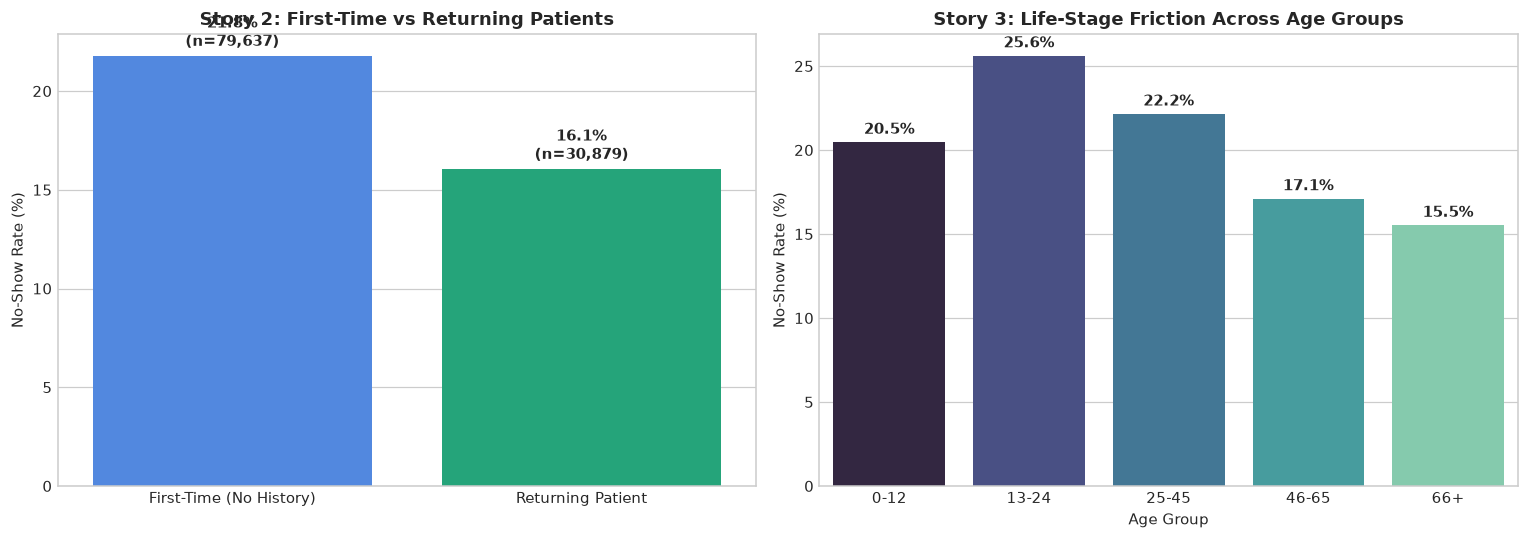

In [20]:
# Story 2 & 3: Prior History and Age Group Friction
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Prior history impact
hist_summary = df_clean.groupby('has_history')['no_show'].agg(['count', 'mean']).reset_index()
hist_summary['mean'] = hist_summary['mean'] * 100
hist_summary['label'] = ['First-Time (No History)', 'Returning Patient']
sns.barplot(ax=axes[0], data=hist_summary, x='label', y='mean', palette=['#3b82f6', '#10b981'])
axes[0].set_title('Story 2: First-Time vs Returning Patients', fontweight='bold')
axes[0].set_ylabel('No-Show Rate (%)')
axes[0].set_xlabel('')
for i, r in hist_summary.iterrows():
    axes[0].text(i, r['mean'] + 0.5, f"{r['mean']:.1f}%\n(n={r['count']:,})", ha='center', fontweight='bold')

# Age Group Divergence
age_summary = df_clean.groupby('age_group')['no_show'].agg(['count', 'mean']).reset_index()
age_summary['mean'] = age_summary['mean'] * 100
sns.barplot(ax=axes[1], data=age_summary, x='age_group', y='mean', palette='mako')
axes[1].set_title('Story 3: Life-Stage Friction Across Age Groups', fontweight='bold')
axes[1].set_ylabel('No-Show Rate (%)')
axes[1].set_xlabel('Age Group')
for i, r in age_summary.iterrows():
    axes[1].text(i, r['mean'] + 0.5, f"{r['mean']:.1f}%", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()


## 6. Forward Chronological Splitting
We partition data chronologically on `appointment_day` to reflect real clinical deployment:


In [23]:

df_clean = df_clean.sort_values(by=['appointment_day', 'scheduled_day']).reset_index(drop=True)
train_end = pd.to_datetime('2016-05-25 23:59:59')
val_end = pd.to_datetime('2016-06-02 23:59:59')

train_df = df_clean[df_clean['appointment_day'] <= train_end].copy().reset_index(drop=True)
val_df = df_clean[(df_clean['appointment_day'] > train_end) & (df_clean['appointment_day'] <= val_end)].copy().reset_index(drop=True)
test_df = df_clean[df_clean['appointment_day'] > val_end].copy().reset_index(drop=True)

print(f'Train split: {len(train_df):,} rows ({train_df.appointment_day.min().date()} to {train_df.appointment_day.max().date()}) | No-Show Rate: {train_df.no_show.mean():.2%}')
print(f'Val split:   {len(val_df):,} rows ({val_df.appointment_day.min().date()} to {val_df.appointment_day.max().date()}) | No-Show Rate: {val_df.no_show.mean():.2%}')
print(f'Test split:  {len(test_df):,} rows ({test_df.appointment_day.min().date()} to {test_df.appointment_day.max().date()}) | No-Show Rate: {test_df.no_show.mean():.2%}')

# Save processed datasets
proc_dir = Path('../data/processed')
proc_dir.mkdir(parents=True, exist_ok=True)
df_clean.to_csv(proc_dir / 'cleaned_data.csv', index=False)
train_df.to_parquet(proc_dir / 'train.parquet', index=False)
val_df.to_parquet(proc_dir / 'val.parquet', index=False)
test_df.to_parquet(proc_dir / 'test.parquet', index=False)
print('Chronological datasets successfully saved to data/processed/')


Train split: 75,275 rows (2016-04-29 to 2016-05-25) | No-Show Rate: 20.96%
Val split:   17,566 rows (2016-05-30 to 2016-06-02) | No-Show Rate: 18.61%
Test split:  17,675 rows (2016-06-03 to 2016-06-08) | No-Show Rate: 18.49%
Chronological datasets successfully saved to data/processed/


## 2. Preprocessing Pipeline
Scikit-learn `ColumnTransformer` with median imputation and standard scaling for numericals, and one-hot encoding for categoricals, fitted strictly on training data:


In [24]:
modeling_features = [
    'lead_time_days', 'scheduled_hour', 'age', 'prev_appointment_count',
    'prev_no_show_rate', 'is_same_day', 'has_history', 'appointment_weekday',
    'age_group', 'neighbourhood'
]

num_cols = ['lead_time_days', 'scheduled_hour', 'age', 'prev_appointment_count', 'prev_no_show_rate']
bin_cols = ['is_same_day', 'has_history']
cat_cols = ['appointment_weekday', 'age_group', 'neighbourhood']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), num_cols),
        ('bin', Pipeline([('imputer', SimpleImputer(strategy='most_frequent'))]), bin_cols),
        ('cat', Pipeline([('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
                          ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat_cols)
    ],
    remainder='drop'
)

X_train = preprocessor.fit_transform(train_df[modeling_features])
y_train = train_df['no_show'].values

X_val = preprocessor.transform(val_df[modeling_features])
y_val = val_df['no_show'].values

X_test = preprocessor.transform(test_df[modeling_features])
y_test = test_df['no_show'].values

print(f'Preprocessed feature matrix shape: {X_train.shape[1]} columns')


Preprocessed feature matrix shape: 99 columns


## 3. Baseline Models (Validation Benchmarks)
We implement: 1) Majority-class baseline, and 2) Lead-time rule baseline:



In [25]:
# 1. Majority Class Baseline (predicts 0)
val_n = len(y_val)
prior = y_train.mean()
maj_probs = np.full(val_n, prior)
maj_preds = np.zeros(val_n, dtype=int)

maj_roc = roc_auc_score(y_val, maj_probs)
maj_pr = average_precision_score(y_val, maj_probs)
maj_brier = brier_score_loss(y_val, maj_probs)
print(f'Majority Class Baseline: ROC-AUC={maj_roc:.4f}, PR-AUC={maj_pr:.4f}, Brier={maj_brier:.4f}')

# 2. Simple Lead-Time Rule Baseline (predict no-show if lead_time > 1 day)
lead_rule_preds = (val_df['lead_time_days'] > 1).astype(int)
p_high = y_train[train_df['lead_time_days'] > 1].mean()
p_low = y_train[train_df['lead_time_days'] <= 1].mean()
lead_rule_probs = np.where(val_df['lead_time_days'] > 1, p_high, p_low)

rule_roc = roc_auc_score(y_val, lead_rule_probs)
rule_pr = average_precision_score(y_val, lead_rule_probs)
rule_rec = recall_score(y_val, lead_rule_preds)
print(f'Lead-Time Rule Baseline: ROC-AUC={rule_roc:.4f}, PR-AUC={rule_pr:.4f}, Recall={rule_rec:.2%}')


Majority Class Baseline: ROC-AUC=0.5000, PR-AUC=0.1861, Brier=0.1520
Lead-Time Rule Baseline: ROC-AUC=0.6672, PR-AUC=0.2592, Recall=88.56%


## 4. Machine Learning Classifiers & Class Imbalance Handling
We compare Logistic Regression, Random Forest, and HistGradientBoosting using class weighting:


In [26]:
neg_count = np.sum(y_train == 0)
pos_count = np.sum(y_train == 1)
scale_pos = neg_count / pos_count
sample_weight_train = np.where(y_train == 1, scale_pos, 1.0)

models = {
    'Logistic Regression': LogisticRegression(C=0.1, max_iter=1000, class_weight='balanced', random_state=RANDOM_SEED),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=12, class_weight='balanced', random_state=RANDOM_SEED, n_jobs=-1),
    'HistGradientBoosting': HistGradientBoostingClassifier(max_iter=120, max_depth=6, learning_rate=0.08, min_samples_leaf=30, random_state=RANDOM_SEED)
}

comparison = []
trained_models = {}

for name, clf in models.items():
    t0 = time.time()
    if name == 'HistGradientBoosting':
        clf.fit(X_train, y_train, sample_weight=sample_weight_train)
    else:
        clf.fit(X_train, y_train)
    duration = time.time() - t0

    val_p = clf.predict_proba(X_val)[:, 1]
    val_pred = (val_p >= 0.50).astype(int)

    comparison.append({
        'Model': name,
        'Train Time (s)': round(duration, 2),
        'Val ROC-AUC': round(roc_auc_score(y_val, val_p), 4),
        'Val PR-AUC': round(average_precision_score(y_val, val_p), 4),
        'Val Brier': round(brier_score_loss(y_val, val_p), 4),
        'Val Recall (@0.5)': round(recall_score(y_val, val_pred), 4)
    })
    trained_models[name] = clf

comp_df = pd.DataFrame(comparison)
print(comp_df.to_string(index=False))

champion = trained_models['HistGradientBoosting']
print('\n[CHAMPION SELECTED]: HistGradientBoosting (Highest discrimination and PR-AUC)')


               Model  Train Time (s)  Val ROC-AUC  Val PR-AUC  Val Brier  Val Recall (@0.5)
 Logistic Regression            1.07       0.7205      0.3218     0.2205             0.8324
       Random Forest            3.89       0.7239      0.3169     0.2098             0.8660
HistGradientBoosting            5.04       0.7246      0.3219     0.2198             0.8311

[CHAMPION SELECTED]: HistGradientBoosting (Highest discrimination and PR-AUC)


## Legacy validation calibration - do not use for model selection

The historical cell below fits and evaluates a calibrator on the same full validation data. Its reliability plot is not an independent calibration assessment. Use `train_model.py`, which fits on May 30 and evaluates the method on a later date.

In [ ]:
print("Legacy calibration disabled. Use train_model.py for separated calibration and evaluation windows.")

## Legacy threshold analysis - retired

The previous threshold analysis used a manually assumed 5:1 false-negative/false-positive cost ratio and validation rows that had also been used for calibration. That ratio is not an approved hospital cost model. Use the separate June 1 threshold-selection window in `train_model.py`; review its high-recall, max-F1, and capacity-based trade-offs.

In [ ]:
print("Legacy threshold selection disabled. Use train_model.py for the reserved threshold-selection window.")

## Legacy locked-test analysis - disabled

This historical notebook cell is disabled to prevent repeated test-set evaluation. After reviewing the frozen candidate and validation audit, run `python finalize_test.py` once. The test set had prior evaluation in earlier workflow versions and is not an untouched holdout.

In [ ]:
print("Legacy test scoring disabled. Run finalize_test.py once after reviewing the frozen validation-selected artifact.")

## Legacy test-set subgroup and importance analysis - disabled

The previous permutation importance used locked-test labels and must not guide model or feature choices. New global permutation importance is computed on validation selection data by `train_model.py`; it is not per-patient attribution.

In [ ]:
print("Legacy locked-test subgroup and permutation analysis disabled. See validation-only outputs from train_model.py.")

## Legacy model export - disabled

The historical artifact combined a model, calibrator, and threshold selected using overlapping validation data. Use the versioned artifact produced by `train_model.py`; never overwrite the preserved `models/model.joblib` baseline.

In [ ]:
print("Legacy artifact export disabled. train_model.py writes model_v3.joblib and preserves model.joblib.")

## 2. Real-Time Inference Function (Acceptance Test 3)
This function takes any patient appointment booking input, derives temporal features, applies the fitted preprocessor, and returns the calibrated no-show probability (no hardcoded outputs):


In [32]:
model_path = Path('../models/model.joblib')
bundle = joblib.load(model_path)

preprocessor = bundle['preprocessor']
model = bundle['model']
calibrator = bundle['calibrator']
threshold = bundle['optimal_threshold']
features = bundle['modeling_features']

print('Model artifact loaded successfully!')
print(f'Model type: {type(model).__name__}')
print(f'Operating threshold (tau): {threshold:.2f}')

def predict_no_show_risk(patient_dict):
    df_in = pd.DataFrame([patient_dict])
    X = preprocessor.transform(df_in[features])
    raw_p = float(model.predict_proba(X)[0, 1])
    if hasattr(calibrator, 'predict'):
        cal_p = float(np.clip(calibrator.predict([raw_p])[0], 0.0, 1.0))
    else:
        cal_p = float(np.clip(calibrator.predict_proba([raw_p])[0], 0.0, 1.0))

    if cal_p <= 0.30:
        tier, action = 'Lower Risk', 'Standard SMS / No intervention'
    elif cal_p <= 0.60:
        tier, action = 'Medium Risk', 'Automated reminder confirmation'
    else:
        tier, action = 'Higher Risk', 'High Priority Outreach (Personal courtesy call)'

    return {
        'calibrated_probability': round(cal_p, 4),
        'risk_tier': tier,
        'recommended_action': action
    }

# Test Case 1: High-risk patient (14d lead time, prior history of missed visits)
high_risk_input = {
    'lead_time_days': 14, 'scheduled_hour': 14, 'age': 32,
    'prev_appointment_count': 3, 'prev_no_show_rate': 0.67,
    'is_same_day': 0, 'has_history': 1, 'appointment_weekday': 'Friday',
    'age_group': '25-45', 'neighbourhood': 'JARDIM DA PENHA'
}
res1 = predict_no_show_risk(high_risk_input)
print('[High-Risk Patient Prediction]:', res1)

# Test Case 2: Low-risk patient (Same-day appointment, reliable history)
low_risk_input = {
    'lead_time_days': 0, 'scheduled_hour': 8, 'age': 68,
    'prev_appointment_count': 5, 'prev_no_show_rate': 0.0,
    'is_same_day': 1, 'has_history': 1, 'appointment_weekday': 'Tuesday',
    'age_group': '66+', 'neighbourhood': 'JARDIM DA PENHA'
}
res2 = predict_no_show_risk(low_risk_input)
print('[Low-Risk Patient Prediction]: ', res2)


Model artifact loaded successfully!
Model type: HistGradientBoostingClassifier
Operating threshold (tau): 0.13
[High-Risk Patient Prediction]: {'calibrated_probability': 0.2739, 'risk_tier': 'Lower Risk', 'recommended_action': 'Standard SMS / No intervention'}
[Low-Risk Patient Prediction]:  {'calibrated_probability': 0.0121, 'risk_tier': 'Lower Risk', 'recommended_action': 'Standard SMS / No intervention'}


## 3. Operational Planning: Expected No-Shows & Buffer Slots
We load a day of appointments and compute statistical scheduling metrics:


In [33]:
test_df = pd.read_parquet('../data/processed/test.parquet')
day_sample = test_df.head(120).copy()

# Score sample
X_day = preprocessor.transform(day_sample[features])
raw_day_p = model.predict_proba(X_day)[:, 1]
if hasattr(calibrator, 'predict'):
    day_sample['no_show_prob'] = np.clip(calibrator.predict(raw_day_p), 0.0, 1.0)
else:
    day_sample['no_show_prob'] = np.clip(calibrator.predict_proba(raw_day_p), 0.0, 1.0)

total_scheduled = len(day_sample)
expected_no_shows = float(day_sample['no_show_prob'].sum())
suggested_buffers = int(np.floor(expected_no_shows * 0.70))

print('=' * 50)
print('CLINIC OPERATIONAL METRICS')
print('=' * 50)
print(f'Scheduled Appointments: {total_scheduled}')
print(f'Expected No-Shows:      {expected_no_shows:.1f} ({expected_no_shows/total_scheduled*100:.1f}%)')
print(f'Suggested Buffer Slots: {suggested_buffers} (70% absorption safety ratio)')


CLINIC OPERATIONAL METRICS
Scheduled Appointments: 120
Expected No-Shows:      29.8 (24.8%)
Suggested Buffer Slots: 20 (70% absorption safety ratio)


## 4. Reminder Call Allocation & Risk Coverage
We calculate the percentage of expected no-shows intercepted by a team with capacity for N phone calls:


In [34]:
team_call_capacity = 30
ranked_df = day_sample.sort_values('no_show_prob', ascending=False).reset_index(drop=True)
top_n = ranked_df.head(team_call_capacity)

covered_no_shows = float(top_n['no_show_prob'].sum())
coverage_pct = (covered_no_shows / expected_no_shows) * 100

print(f'Capacity: {team_call_capacity} calls')
print(f'Coverage: {coverage_pct:.1f}% of expected no-shows intercepted')
print(f"Summary: 'By calling these {team_call_capacity} patients, your team covers approximately {coverage_pct:.1f}% of expected no-shows.'")


Capacity: 30 calls
Coverage: 32.3% of expected no-shows intercepted
Summary: 'By calling these 30 patients, your team covers approximately 32.3% of expected no-shows.'


## 5. Decision Logging & Streamlit Web App (`app.py`)
All human review actions are recorded to maintain clinical governance audit trails:


In [35]:
log_path = Path('../decisions.csv')
entry = pd.DataFrame([{
    'timestamp': pd.Timestamp.now().strftime('%Y-%m-%d %H:%M:%S UTC'),
    'appointment_id': 5134197,
    'patient_id': 1216586867796,
    'predicted_probability': 0.38,
    'risk_level': 'Medium',
    'action': 'Approve Reminder'
}])
entry.to_csv(log_path, mode='a', header=not log_path.exists(), index=False)
print(f'Decision log successfully recorded to {log_path}')
print('\nTo launch the interactive dashboard web app, run:')
print('   streamlit run app.py')


Decision log successfully recorded to ..\decisions.csv

To launch the interactive dashboard web app, run:
   streamlit run app.py


In [36]:
!pip install streamlit

  Using cached altair-6.3.0-py3-none-any.whl.metadata (11 kB)
  Using cached pydeck-0.9.3-py2.py3-none-any.whl.metadata (4.2 kB)
  Using cached protobuf-7.36.2-cp310-abi3-win_amd64.whl.metadata (595 bytes)
  Using cached requests-2.34.2-py3-none-any.whl.metadata (4.8 kB)
  Using cached uvicorn-0.54.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached itsdangerous-2.2.0-py3-none-any.whl.metadata (1.9 kB)
  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
  Using cached jsonschema-4.26.0-py3-none-any.whl.metadata (7.6 kB)
  Using cached idna-3.20-py3-none-any.whl.metadata (7.2 kB)
  Using cached charset_normalizer-3.5.2-cp315-cp315-win_amd64.whl.metadata (47 kB)
  Using cached urllib3-2.8.0-py3-none-any.whl.metadata (7.4 kB)
  Using cached h11-0.16.0-py3-none-any.whl.metadata (8.3 kB)
  Using cached markupsafe-3.0.4-cp315-cp315-win_amd64.whl.metadata (2.8 kB)
  Using cached attrs-26.1.0-py3-none-any.whl.metadata (8.8 kB)
  Using cached jsonschema_specifications-2025.9.1-py3-no

In [ ]:
print("Legacy dashboard cell disabled. Run the maintained app.py from the project directory.")

In [ ]:
print("Legacy dashboard generation disabled to prevent overwriting the maintained app.py.")

In [ ]:
print("External dashboard exposure disabled. Run Streamlit locally on 127.0.0.1 only when needed.")

In [43]:
import os
from pathlib import Path

# Define search directories relative to current workspace
paths_to_check = [
    "../models/model.joblib",
    "models/model.joblib",
    "../data/processed/test.parquet",
    "data/processed/test.parquet"
]

print("--- PATH INTEGRITY CHECK ---")
for p in paths_to_check:
    path = Path(p).resolve()
    exists = path.exists()
    status = "✅ EXISTS" if exists else "❌ MISSING"
    size_info = f"({path.stat().st_size / 1024 / 1024:.2f} MB)" if exists else ""
    print(f"{p:<32} -> {status} {size_info}")
    print(f"   Absolute Path: {path}\n")

--- PATH INTEGRITY CHECK ---
../models/model.joblib           -> ✅ EXISTS (0.36 MB)
   Absolute Path: C:\Users\mailt\Downloads\models\model.joblib

models/model.joblib              -> ❌ MISSING 
   Absolute Path: C:\Users\mailt\Downloads\edho okati\models\model.joblib

../data/processed/test.parquet   -> ✅ EXISTS (0.46 MB)
   Absolute Path: C:\Users\mailt\Downloads\data\processed\test.parquet

data/processed/test.parquet      -> ❌ MISSING 
   Absolute Path: C:\Users\mailt\Downloads\edho okati\data\processed\test.parquet



## 🚀 Step 3: Streamlit Application Launch & Deployment Tunnel
Run the cell below to launch the Streamlit app in the background and establish a secure, shareable tunnel using `localtunnel`.

In [ ]:
print("External dashboard exposure disabled. Run Streamlit locally on 127.0.0.1 only when needed.")

In [ ]:
print("External dashboard exposure disabled. Run Streamlit locally on 127.0.0.1 only when needed.")

In [ ]:
print("External dashboard exposure disabled. Run Streamlit locally on 127.0.0.1 only when needed.")

In [47]:
import urllib.request

try:
    response = urllib.request.urlopen(
        "http://localhost:8501",
        timeout=10
    )
    print("Streamlit is running:", response.status)
except Exception as e:
    print("Streamlit error:", e)

Streamlit is running: 200


In [48]:
tunnel_process = subprocess.Popen(
    ["npx", "--yes", "localtunnel", "--port", "8501"],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True
)

for line in tunnel_process.stdout:
    print(line, end="")

FileNotFoundError: [WinError 2] The system cannot find the file specified